# Hito 2  -  Proceso KDD: Selección, Integración Open Data, Preproceso, EDA y Tarjeta de Datos
**Proyecto:** Impacto de las Redes Sociales en el Bienestar y Rendimiento Estudiantil  
**Dataset Base:** *Impact of Social Media on Life* (`impact_of_social_media_on_life.csv`, $N = 4.500$, $d = 16$)  
**Fecha de Entrega:** 27 de Noviembre de 2026  

---
### Arquitectura Modular del Notebook (Distribución de Carga entre 5 Integrantes)
* **Módulo 0:** Configuración del entorno e ingesta reproducible del dataset.
* **Módulo 1 (Persona 1  -  Ingesta e Integración):** Selección de variables base, depuración de identificadores (`Student_ID`) e integración *Macro-to-Micro* con fuentes Open Data españolas (**INE**, **SIIU / Ministerio de Universidades** y **OEDA - Encuesta ESTUDES**).
* **Módulo 2 (Persona 2  -  Calidad del Dato y EDA):** Auditoría de completitud, validación de restricciones lógicas de dominio ($\le 24	ext{h}$), detección híbrida de anomalías (**IQR** + **Local Outlier Factor - LOF**) y Análisis Exploratorio de Datos (EDA) orientado a contrastar la hipótesis $H_1$.
* **Módulo 3 (Persona 3  -  Transformación y Feature Engineering):** Agregaciones temporales (`Weekly_Total_Hours`, `Weekend_Binge_Ratio`), índices de dominio (`DSDI`, `CWU`, `Relative_Usage_Delta`), discretización clínica (umbrales PSS de Cohen vs. cuantiles), codificación y escalado sin fuga de datos.
* **Módulo 4 (Persona 4  -  Reducción Dimensional y Tarjeta de Datos):** Selección de características (*Mutual Information* y *Random Forest Importance*), análisis de componentes principales (**PCA**), particionamiento estratificado (*Holdout* 70/30 + *10-fold CV*) y exportación de las Vistas Minables (`tarjeta_datos_arboles.csv` y `tarjeta_datos_distancias.csv`).
* **Módulo 5 (Persona 5  -  Líneas de Trabajo Baseline):** Prototipos iniciales de las 4 líneas de minería de datos (Clasificación, Regresión con Ablación, Clustering Fenotípico y Perturbaciones Contrafactuales).

> **Fuente y alcance de Hito 2 (revisión del 23-11-2026):** se utiliza exclusivamente la copia pública fijada y auditada en Módulo 1 (4500 filas), cuya equivalencia bit a bit con Kaggle NO está certificada. Los indicadores de INE, SIIU y ESTUDES se usan solo para contextualización descriptiva, no como variables predictoras. El cuaderno detiene su ejecución si no puede verificar la fuente y no fabrica datos.


In [1]:
# ==============================================================================
# MÓDULO 0: CONFIGURACIÓN DEL ENTORNO E INGESTA REPRODUCIBLE
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, f1_score, mean_squared_error, r2_score, silhouette_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
RANDOM_SEED = 42

print("Librerías cargadas correctamente. Semilla global:", RANDOM_SEED)

Librerías cargadas correctamente. Semilla global: 42


In [2]:
# MÓDULO 0 - ORIGEN REPRODUCIBLE: NO GENERAR REGISTROS SINTÉTICOS
from pathlib import Path
import sys
import pandas as pd

repo_root = Path.cwd().resolve()
modulo1_root = repo_root / "modulo1_abdelmouiz_kobry"
if not (modulo1_root / "fuente_auditoria.py").is_file():
    raise RuntimeError("Falta Módulo 1. Ejecuta este notebook desde la raíz del repositorio.")
if str(modulo1_root) not in sys.path:
    sys.path.insert(0, str(modulo1_root))

from fuente_auditoria import ARCHIVO_LOCAL, descargar_espejo, cargar_y_auditar
from ejecutar_modulo1 import ejecutar

if not ARCHIVO_LOCAL.is_file():
    print("Descargando espejo público fijado en Módulo 1; no se crearán datos artificiales.")
    descargar_espejo(ARCHIVO_LOCAL)

# Fallar ante un CSV distinto: esquema, contenido y Git blob fijados por Módulo 1.
df_raw, auditoria_m1 = cargar_y_auditar(ARCHIVO_LOCAL, exigir_version_referencia=True)
evidencia_m1 = ejecutar(ARCHIVO_LOCAL, modulo1_root / "outputs", version_publica=True)
base_normalizada = modulo1_root / "outputs" / "modulo1_base_normalizada.csv"
df_base = pd.read_csv(base_normalizada)
if df_raw.shape != (4500, 16) or df_base.shape != (4500, 15):
    raise AssertionError("La fuente verificada o la normalización no cumplen el esquema requerido.")
if df_base["Academic_Performance_GPA"].isna().sum() != 85 or df_base["Perceived_Stress_Score"].isna().sum() != 46:
    raise AssertionError("Cambió la distribución esperada de valores ausentes.")
print("Fuente Módulo 1 verificada:", len(df_base), "filas,", len(df_base.columns), "columnas base.")
print("Origen: espejo público GitHub con blob fijado. NO se certifica equivalencia con Kaggle.")


Descargando espejo público fijado en Módulo 1; no se crearán datos artificiales.


Fuente Módulo 1 verificada: 4500 filas, 15 columnas base.
Origen: espejo público GitHub con blob fijado. NO se certifica equivalencia con Kaggle.


---
## Módulo 1 (Persona 1): Selección e integración contextual auditada

- Fuente de entrada: copia pública fijada (4500 registros, 16 columnas), comprobada contra el Git Blob SHA y el esquema de `fuente_auditoria.py`. **No es una descarga certificada de Kaggle**.
- La normalización oficial elimina `Student_ID`, conserva los dos objetivos y no imputa nulos.
- `integracion_contextual.py` ejecuta tres `LEFT JOIN` con agregados españoles de INE 2025, SIIU 2024/25 y ESTUDES 2025, sin perder observaciones. Las estadísticas no representan a los mismos encuestados y no son predictoras individuales.
- Los siguientes módulos trabajan exclusivamente sobre `df_base`, sin anexar los indicadores contextuales al vector de entrenamiento.


In [3]:
# MÓDULO 1 - Indicadores macro solo para DESCRIPCIÓN; nunca predictores
from integracion_contextual import integrar_contexto, COLUMNAS_CONTEXTO

df_contexto, cobertura_contexto = integrar_contexto(df_base)
assert len(df_contexto) == len(df_base) == 4500
assert all(c not in df_base.columns for c in COLUMNAS_CONTEXTO)
print("Integración contextual (sin modificar df_base):", cobertura_contexto["cobertura"])
display(df_contexto[["Age", "Academic_Level", *COLUMNAS_CONTEXTO]].head(4))


Integración contextual (sin modificar df_base): {'INE_Redes_Sociales_Participacion_Pct_2025': 4336, 'SIIU_Nota_Expediente_Grado_10_2024_25': 2777, 'ESTUDES_RRSS_Uso_Problematico_Pct_2025': 1265}


,Age,Academic_Level,INE_Redes_Sociales_Participacion_Pct_2025,SIIU_Nota_Expediente_Grado_10_2024_25,ESTUDES_RRSS_Uso_Problematico_Pct_2025
0,19,Undergrad,69.5,7.42,NaN
1,19,Undergrad,69.5,7.42,NaN
2,17,High School,69.5,NaN,15.1
3,16,High School,69.5,NaN,15.0


---
## Módulo 2 (Persona 2): Calidad del Dato, Detección de Anomalías y EDA
Se audita la integridad física del conjunto de datos y se contrasta la **Hipótesis Principal ($H_1$)**: el deterioro psicométrico y académico no crece linealmente con las horas de pantalla, sino que presenta un punto de inflexión ($>3.5	ext{h}$) mediado por la nocturnidad (`Late_Night_Usage`) y la comparación social.

In [4]:
from pathlib import Path
import pandas as pd

ruta_base = Path("modulo1_abdelmouiz_kobry/outputs/modulo1_base_normalizada.csv")
df_base = pd.read_csv(ruta_base)

print(f"Filas: {len(df_base)}")
print(f"Columnas: {len(df_base.columns)}")
print(f"Filas duplicadas exactas: {df_base.duplicated().sum()}")
print(f"Filas con al menos un valor ausente: {df_base.isna().any(axis=1).sum()}")

nulos = df_base.isna().sum()
auditoria = pd.DataFrame({
    "Valores ausentes": nulos,
    "Porcentaje (%)": (100 * nulos / len(df_base)).round(2)
})

display(auditoria.sort_values("Valores ausentes", ascending=False))

Filas: 4500
Columnas: 15
Filas duplicadas exactas: 0
Filas con al menos un valor ausente: 131


,Valores ausentes,Porcentaje (%)
Academic_Performance_GPA,85,1.89
Perceived_Stress_Score,46,1.02
Age,0,0.00
Primary_Platform,0,0.00
Daily_Usage_Hours,0,0.00
Gender,0,0.00
Academic_Level,0,0.00
Device_Type,0,0.00
Weekend_Extra_Hours,0,0.00
Sleep_Duration_Hours,0,0.00


In [5]:
# Comprobación de la regla: uso diario de redes + sueño ≤ 24 horas
uso = df_base["Daily_Usage_Hours"]
sueno = df_base["Sleep_Duration_Hours"]
total_horas = uso + sueno

print("Filas comprobadas:", total_horas.notna().sum())
print("Filas sin datos suficientes:", total_horas.isna().sum())
print("Filas que superan las 24 horas:", (total_horas > 24).sum())
print("Máxima suma observada:", total_horas.max(), "horas")

Filas comprobadas: 4500
Filas sin datos suficientes: 0
Filas que superan las 24 horas: 0
Máxima suma observada: 19.5 horas


In [6]:
# Detección de valores atípicos por variable mediante IQR
variables = [
    "Daily_Usage_Hours",
    "Weekend_Extra_Hours",
    "Sleep_Duration_Hours",
    "Perceived_Stress_Score",
    "Mental_Health_Index",
    "Academic_Performance_GPA",
]

resultados_iqr = []

for variable in variables:
    datos = df_base[variable].dropna()
    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    atipicos = (datos < limite_inferior) | (datos > limite_superior)

    resultados_iqr.append({
        "Variable": variable,
        "Datos evaluados": len(datos),
        "Límite inferior": limite_inferior,
        "Límite superior": limite_superior,
        "Atípicos": atipicos.sum(),
        "% de atípicos": 100 * atipicos.mean(),
    })

display(pd.DataFrame(resultados_iqr).round(2))

,Variable,Datos evaluados,Límite inferior,Límite superior,Atípicos,% de atípicos
0,Daily_Usage_Hours,4500,-1.40,11.40,162,3.60
1,Weekend_Extra_Hours,4500,-0.20,3.80,10,0.22
2,Sleep_Duration_Hours,4500,3.75,9.75,72,1.60
3,Perceived_Stress_Score,4454,-4.50,31.50,75,1.68
4,Mental_Health_Index,4500,46.50,114.50,85,1.89
5,Academic_Performance_GPA,4415,2.42,4.50,68,1.54


In [7]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Usamos las mismas seis variables que en el IQR.
datos_lof = df_base[variables].dropna()
datos_escalados = StandardScaler().fit_transform(datos_lof)

modelo_lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
etiquetas = modelo_lof.fit_predict(datos_escalados)

# 1 = atípico, 0 = habitual, <NA> = registro sin evaluar
df_base["LOF_Outlier_Flag"] = pd.Series(pd.NA, index=df_base.index, dtype="Int64")
df_base.loc[datos_lof.index, "LOF_Outlier_Flag"] = (etiquetas == -1).astype(int)

print("Registros evaluados:", len(datos_lof))
print("Registros sin evaluar:", df_base["LOF_Outlier_Flag"].isna().sum())
print("Registros marcados como atípicos:", (etiquetas == -1).sum())

Registros evaluados: 4369
Registros sin evaluar: 131
Registros marcados como atípicos: 88


> **Auditoría antigua desactivada:** esta celda repetía IQR y LOF utilizando `df_integrated`, que procedía del generador sintético eliminado. El análisis válido de Módulo 2 está en las celdas anteriores (`df_base`, IQR y LOF); se conservan sin cambios las celdas y gráficos de Ernesto.


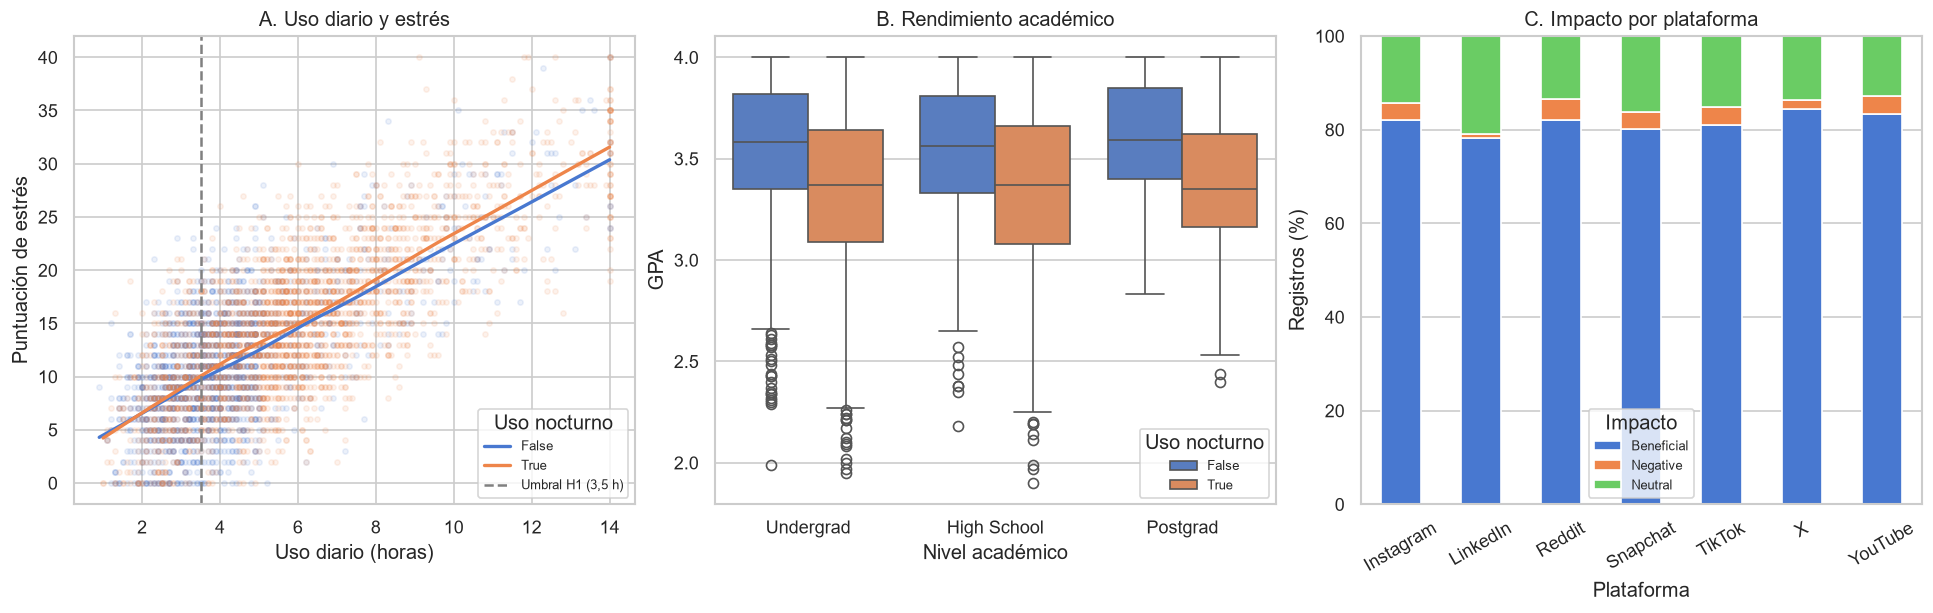

Figura guardada en: C:\Users\Abdelmouiz Kobry\MD_NOTEBOOK_FIX_20261123_114109\verification\execution\run\Figura_1_EDA_H1.png


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ejes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained")

# A. Uso diario y estrés, con una curva LOWESS por grupo de uso nocturno
for grupo, datos in df_base.groupby("Late_Night_Usage"):
    sns.regplot(
        data=datos,
        x="Daily_Usage_Hours",
        y="Perceived_Stress_Score",
        lowess=True,
        scatter_kws={"alpha": 0.10, "s": 10},
        line_kws={"label": str(grupo), "linewidth": 2},
        ax=ejes[0],
    )

ejes[0].axvline(3.5, color="gray", linestyle="--", label="Umbral H1 (3,5 h)")
ejes[0].set(title="A. Uso diario y estrés", xlabel="Uso diario (horas)",
            ylabel="Puntuación de estrés")
ejes[0].legend(title="Uso nocturno", fontsize=8)

# B. Distribución del rendimiento académico
sns.boxplot(
    data=df_base,
    x="Academic_Level",
    y="Academic_Performance_GPA",
    hue="Late_Night_Usage",
    ax=ejes[1],
)
ejes[1].set(title="B. Rendimiento académico", xlabel="Nivel académico", ylabel="GPA")
ejes[1].legend(title="Uso nocturno", fontsize=8)

# C. Porcentaje de cada categoría de impacto dentro de cada plataforma
impacto = pd.crosstab(df_base["Primary_Platform"], df_base["Overall_Impact"],
                      normalize="index") * 100
impacto.plot.bar(stacked=True, ax=ejes[2], rot=30)
ejes[2].set(title="C. Impacto por plataforma", xlabel="Plataforma",
            ylabel="Registros (%)", ylim=(0, 100))
ejes[2].legend(title="Impacto", fontsize=8)

ruta_figura = Path("Figura_1_EDA_H1.png")
fig.savefig(ruta_figura, dpi=300, bbox_inches="tight")
plt.show()
print("Figura guardada en:", ruta_figura.resolve())

---
## Módulo 3 (Persona 3): Ingeniería de Características, Discretización y Escalado
Se construyen variables compuestas derivadas del conocimiento de dominio del Hito 1:
* `Weekly_Total_Hours`: Carga semanal agregada ($5 \cdot 	ext{Daily} + 2 \cdot (	ext{Daily} + 	ext{Weekend})$).
* `Weekend_Binge_Ratio`: Proporción de intensificación digital en fin de semana.
* `DSDI` (*Digital Sleep Debt Index*): Deuda de sueño ponderada por nocturnidad y calidad subjetiva.
* `CWU` (*Comparison-Weighted Usage*): Interacción multiplicativa entre horas diarias y frecuencia de comparación social.
* `PSS_Clinical_Tier`: Discretización clínica de Cohen et al. (1983) frente a particiones estadísticas.

Nota: los indicadores macro INE/SIIU/ESTUDES no forman parte de las 29 variables predictoras de Módulo 3.


In [9]:
def engineer_features(df):
    d = df.copy()
    comp_map = {'Never': 0, 'Rarely': 1, 'Sometimes': 2, 'Often': 3, 'Always': 4}
    lvl_map = {'High School': 1, 'Undergrad': 2, 'Postgrad': 3}

    d['Social_Comparison_Ord'] = d['Social_Comparison_Frequency'].map(comp_map)
    d['Academic_Level_Ord'] = d['Academic_Level'].map(lvl_map)
    d['Late_Night_Int'] = d['Late_Night_Usage'].astype(float)

    assert d['Social_Comparison_Ord'].notna().all(), d['Social_Comparison_Frequency'].unique()
    assert d['Academic_Level_Ord'].notna().all(), d['Academic_Level'].unique()

    d['Weekly_Total_Hours'] = np.round(5*d['Daily_Usage_Hours'] + 2*(d['Daily_Usage_Hours'] + d['Weekend_Extra_Hours']), 2)
    d['Weekend_Binge_Ratio'] = np.round(d['Weekend_Extra_Hours'] / (d['Daily_Usage_Hours'] + 0.1), 3)
    d['DSDI'] = np.round((np.maximum(0, 8.0 - d['Sleep_Duration_Hours']) * (1.0 + 0.5*d['Late_Night_Int'])) / d['Sleep_Quality_Score'], 3)
    d['CWU'] = np.round(d['Daily_Usage_Hours'] * d['Social_Comparison_Ord'], 2)

    d['PSS_Clinical_Tier'] = pd.cut(d['Perceived_Stress_Score'], bins=[-0.1, 13.0, 26.0, 40.0],
                                    labels=['Bajo (0-13)', 'Moderado (14-26)', 'Alto (27-40)'])
    d['PSS_Clinical_Ord'] = d['PSS_Clinical_Tier'].cat.codes.replace(-1, np.nan)
    return d

df_engineered = engineer_features(df_base)
print("Distribución por Nivel Clínico PSS (Cohen), % sobre 4.500:")
print(df_engineered['PSS_Clinical_Tier'].value_counts(normalize=True, dropna=False).mul(100).round(2))
print(df_engineered[['Weekly_Total_Hours', 'Weekend_Binge_Ratio', 'DSDI', 'CWU']].describe().round(2))

Distribución por Nivel Clínico PSS (Cohen), % sobre 4.500:
PSS_Clinical_Tier
Bajo (0-13)         52.69
Moderado (14-26)    41.22
Alto (27-40)         5.07
NaN                  1.02
Name: proportion, dtype: float64
       Weekly_Total_Hours  Weekend_Binge_Ratio     DSDI      CWU
count             4500.00              4500.00  4500.00  4500.00
mean                40.67                 0.42     1.25    12.04
std                 18.27                 0.28     1.57     8.73
min                  9.20                 0.00     0.00     0.00
25%                 27.50                 0.23     0.19     6.00
50%                 36.70                 0.35     0.60    10.20
75%                 49.50                 0.54     1.58    16.00
max                104.80                 2.83     7.50    56.00


In [10]:
from sklearn.impute import SimpleImputer

# --- Variables numéricas / ordinales y nominales ---
numeric_cols = [
    'Age', 'Academic_Level_Ord', 'Daily_Usage_Hours', 'Weekend_Extra_Hours',
    'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Late_Night_Int',
    'Social_Comparison_Ord', 'Perceived_Stress_Score', 'Mental_Health_Index',
    'Weekly_Total_Hours', 'Weekend_Binge_Ratio', 'DSDI', 'CWU', 'PSS_Clinical_Ord'
]
nominal_cols = ['Gender', 'Primary_Platform', 'Device_Type']

# --- One-Hot Encoding de las nominales ---
X_dummies = pd.get_dummies(df_engineered[nominal_cols], drop_first=False, dtype=int)
X_full = pd.concat([df_engineered[numeric_cols], X_dummies], axis=1)
y_clf = df_engineered['Overall_Impact']
y_reg = df_engineered['Academic_Performance_GPA']

# --- Partición estratificada 70/30 ANTES de imputar y escalar (evita data leakage) ---
X_train, X_test, y_clf_train, y_clf_test, y_reg_train, y_reg_test = train_test_split(
    X_full, y_clf, y_reg, test_size=0.30, random_state=RANDOM_SEED, stratify=y_clf)

# --- Imputación de nulos (mediana), ajustada solo con train ---
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

# --- Doble escalado, ajustado solo con train ---
scaler_z = StandardScaler()
X_train_z = pd.DataFrame(scaler_z.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_z = pd.DataFrame(scaler_z.transform(X_test), columns=X_test.columns, index=X_test.index)

scaler_mm = MinMaxScaler()
X_train_mm = pd.DataFrame(scaler_mm.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_mm = pd.DataFrame(scaler_mm.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Columnas totales:", X_full.shape[1], "| One-Hot:", X_dummies.shape[1])
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Nulos tras imputar (train/test):", X_train.isna().sum().sum(), X_test.isna().sum().sum())
print("Reparto de clases en train (%):")
print(y_clf_train.value_counts(normalize=True).mul(100).round(2))

Columnas totales: 29 | One-Hot: 14
Train: (3150, 29) | Test: (1350, 29)
Nulos tras imputar (train/test): 0 0
Reparto de clases en train (%):
Overall_Impact
Beneficial    81.81
Neutral       14.54
Negative       3.65
Name: proportion, dtype: float64


---
## Módulo 4 (Persona 4): Selección de características, PCA y tarjeta de datos

Se utiliza el conjunto de **29 predictores** y las particiones estratificadas 70/30 ya preparados por Pablo en Módulo 3. No se incluyen estadísticas macro individuales inventadas ni `GPA_Cohort_Delta`, `Relative_Usage_Delta` o `LOF_Outlier_Flag` en las predictoras. Se reutiliza la implementación de Yeni del notebook `modul4-yeni/Entrega_2_Pipeline_KDD_EDA_Preproceso (3).ipynb`. La validación cruzada requiere una revisión adicional de la imputación dentro de cada fold.


,Atributo,Importancia_RF,Informacion_Mutua
8,Perceived_Stress_Score,0.2455,0.3765
9,Mental_Health_Index,0.2089,0.3699
10,Weekly_Total_Hours,0.1146,0.3238
2,Daily_Usage_Hours,0.0856,0.3320
12,DSDI,0.0709,0.2313
4,Sleep_Duration_Hours,0.0548,0.2305
14,PSS_Clinical_Ord,0.0457,0.2295
11,Weekend_Binge_Ratio,0.0335,0.1581
13,CWU,0.0318,0.1852
5,Sleep_Quality_Score,0.0265,0.1827


PCs para >=85% de varianza: 14 de 29 (85.18%)


10-fold CV (Train) -> F1-Macro: 0.8893 (+/- 0.0403)
Predictores: 29 | Train: 3150 | Test: 1350


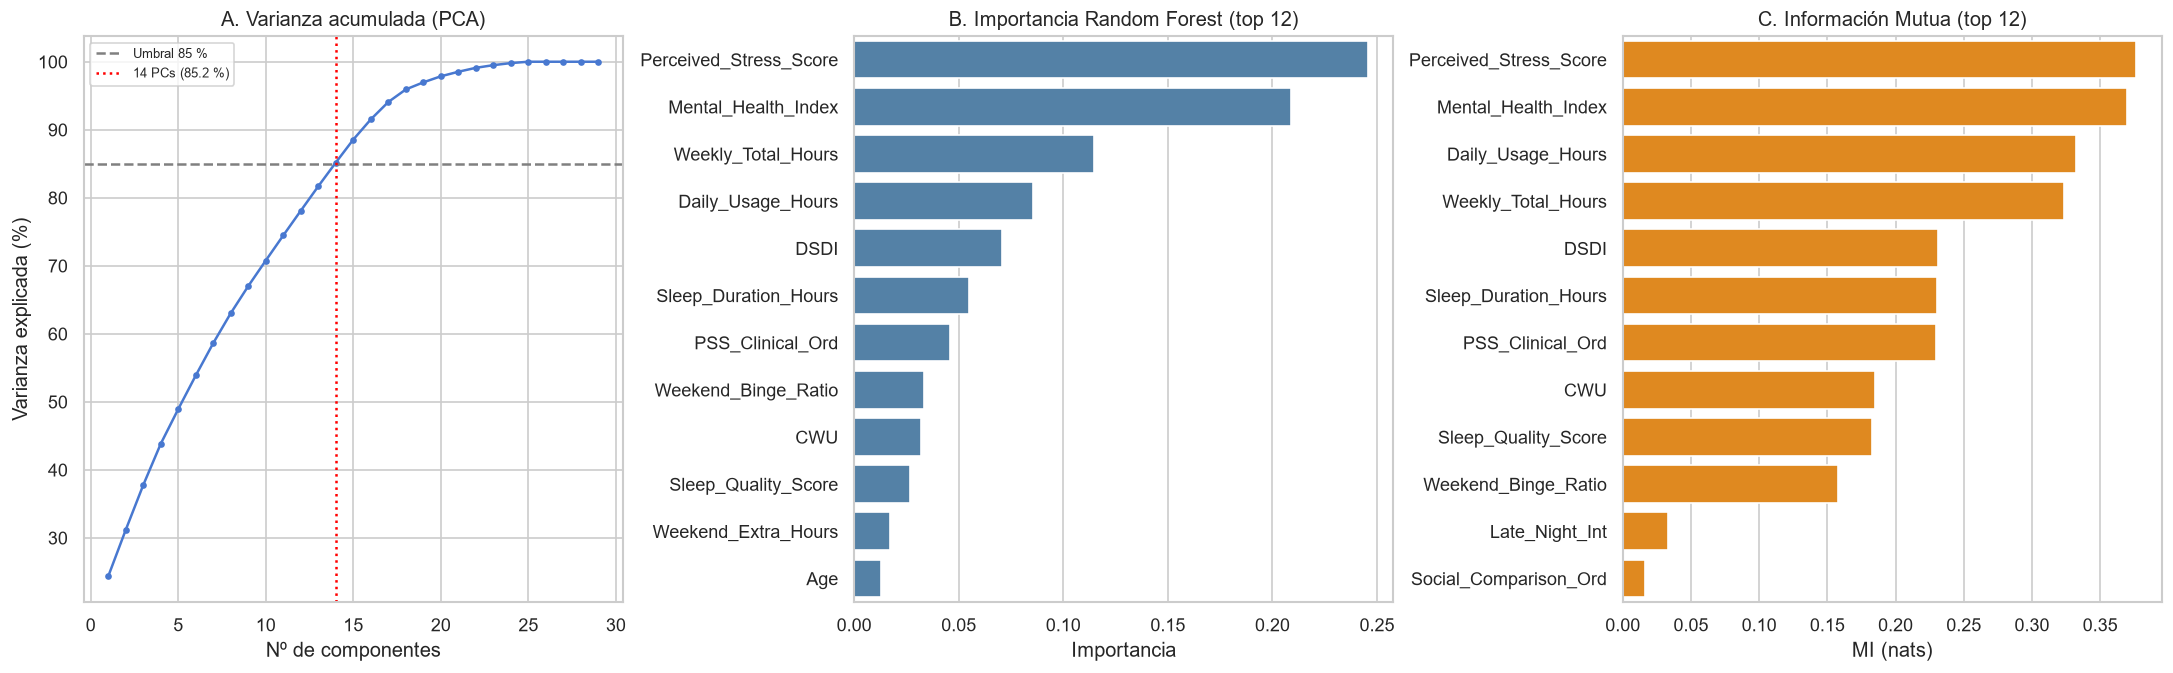

Exportado: (4500, 32)


In [11]:
# ==============================================================================
# MÓDULO 4: SELECCIÓN DE CARACTERÍSTICAS, PCA, CV SIN FUGA Y TARJETA DE DATOS
# (reutiliza X_train/X_test, X_train_z, y_clf_*, y_reg_* del Módulo 3)
# ==============================================================================
from sklearn.pipeline import Pipeline

# --- Ranking: Random Forest + Información Mutua (solo Train) ---
rf_selector = RandomForestClassifier(n_estimators=150, random_state=RANDOM_SEED)
rf_selector.fit(X_train, y_clf_train)
mi_scores = mutual_info_classif(X_train, y_clf_train, random_state=RANDOM_SEED)

ranking_df = pd.DataFrame({
    'Atributo': X_train.columns,
    'Importancia_RF': rf_selector.feature_importances_,
    'Informacion_Mutua': mi_scores
}).sort_values('Importancia_RF', ascending=False)
display(ranking_df.head(12).round(4))

# --- PCA sobre Train estandarizado ---
pca = PCA(random_state=RANDOM_SEED)
pca.fit(X_train_z)
cum_var = np.cumsum(pca.explained_variance_ratio_)
n_85 = int(np.argmax(cum_var >= 0.85) + 1)
print(f"PCs para >=85% de varianza: {n_85} de {X_train.shape[1]} ({cum_var[n_85-1]*100:.2f}%)")

# --- 10-fold CV estratificada sin fuga (escalado dentro de cada fold) ---
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)
pipe_cv = Pipeline([('scaler', StandardScaler()),
                    ('rf', RandomForestClassifier(n_estimators=150, random_state=RANDOM_SEED))])
cv_scores = cross_val_score(pipe_cv, X_train, y_clf_train, cv=cv10, scoring='f1_macro')
print(f"10-fold CV (Train) -> F1-Macro: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print(f"Predictores: {X_train.shape[1]} | Train: {len(X_train)} | Test: {len(X_test)}")

# --- Figura 2 ---
top_rf = ranking_df.head(12)
top_mi = ranking_df.sort_values('Informacion_Mutua', ascending=False).head(12)

fig, ejes = plt.subplots(1, 3, figsize=(18, 5.5), layout='constrained')
ejes[0].plot(range(1, len(cum_var) + 1), cum_var * 100, marker='o', markersize=3)
ejes[0].axhline(85, color='gray', linestyle='--', label='Umbral 85 %')
ejes[0].axvline(n_85, color='red', linestyle=':', label=f'{n_85} PCs ({cum_var[n_85-1]*100:.1f} %)')
ejes[0].set(title='A. Varianza acumulada (PCA)', xlabel='Nº de componentes', ylabel='Varianza explicada (%)')
ejes[0].legend(fontsize=8)
sns.barplot(data=top_rf, y='Atributo', x='Importancia_RF', color='steelblue', ax=ejes[1])
ejes[1].set(title='B. Importancia Random Forest (top 12)', xlabel='Importancia', ylabel='')
sns.barplot(data=top_mi, y='Atributo', x='Informacion_Mutua', color='darkorange', ax=ejes[2])
ejes[2].set(title='C. Información Mutua (top 12)', xlabel='MI (nats)', ylabel='')
fig.savefig('Figura_2_PCA_Ranking.png', dpi=300, bbox_inches='tight')
plt.show()

# --- Exportación de la Tarjeta de Datos ---
tarjeta_datos = pd.concat([X_train.assign(Split='Train'), X_test.assign(Split='Test')]).sort_index()
tarjeta_datos['Target_GPA'] = pd.concat([y_reg_train, y_reg_test]).sort_index()
tarjeta_datos['Target_Overall_Impact'] = pd.concat([y_clf_train, y_clf_test]).sort_index()
tarjeta_datos.to_csv('tarjeta_datos_consolidada_H2.csv', index=False)
print("Exportado:", tarjeta_datos.shape)

---
## Módulo 5 (Persona 5): Verificación Rápida de las Líneas de Trabajo (Baseline Hito 3)
Se ejecutan prototipos de validación cruzada estratificada ($k=10$) sobre la Tarjeta de Datos para confirmar la viabilidad técnica de las líneas supervisadas y no supervisadas planificadas para la siguiente entrega.

In [12]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)

# Línea 1: Clasificación supervisada (Árbol CART vs. k-NN escalado vs. Random Forest)
models_clf = {
    'Árbol Decisión (CART podado)': (DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_SEED), X_train),
    'k-NN (k=11, Min-Max [0,1])': (KNeighborsClassifier(n_neighbors=11, weights='distance'), X_train_mm),
    'Random Forest (150 árboles)': (RandomForestClassifier(n_estimators=150, random_state=RANDOM_SEED), X_train)
}

print("=== BENCHMARK PRELIMINAR LÍNEA 1: CLASIFICACIÓN (10-FOLD CV EN TRAIN) ===")
for name, (clf, X_tr) in models_clf.items():
    scores = cross_val_score(clf, X_tr, y_clf_train, cv=cv10, scoring='f1_macro')
    print(f"{name:<32} -> F1-Macro: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Línea 3: Clustering no supervisado (k-Means sobre subespacio de hábitos y psicometría)
habit_cols = ['Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours',
              'Sleep_Quality_Score', 'Late_Night_Int', 'Social_Comparison_Ord', 'DSDI', 'CWU']
X_hab_z = StandardScaler().fit_transform(X_train[habit_cols])
km = KMeans(n_clusters=4, random_state=RANDOM_SEED, n_init=10)
clusters = km.fit_predict(X_hab_z)
print("\n=== BENCHMARK PRELIMINAR LÍNEA 3: CLUSTERING K-MEANS (k=4) ===")
print(f"Coeficiente de Silueta en subespacio conductual: {silhouette_score(X_hab_z, clusters):.4f}")

=== BENCHMARK PRELIMINAR LÍNEA 1: CLASIFICACIÓN (10-FOLD CV EN TRAIN) ===
Árbol Decisión (CART podado)     -> F1-Macro: 0.8483 (+/- 0.0308)


k-NN (k=11, Min-Max [0,1])       -> F1-Macro: 0.6588 (+/- 0.0568)


Random Forest (150 árboles)      -> F1-Macro: 0.8885 (+/- 0.0417)

=== BENCHMARK PRELIMINAR LÍNEA 3: CLUSTERING K-MEANS (k=4) ===


Coeficiente de Silueta en subespacio conductual: 0.2023
